In [1]:
# The Selkov Oscillator revisited

import PyDSTool as dst
from PyDSTool.Toolbox import phaseplane as pp
import sympy as sp
import matplotlib.pyplot as plt

In [2]:
# 1. Define everything in SymPy
x, y, a, b = sp.symbols('x y a b')

dx = -x + a*y + x**2*y
dy = b - a*y - x**2*y

# 2. Auto-generate varspecs strings for PyDSTool
varspecs = {
    'x': str(dx).replace('**', '^'),
    'y': str(dy).replace('**', '^')
}

# 3. Auto-generate Jacobian strings as a MATRIX STRING
Jxx = str(sp.diff(dx, x)).replace('**', '^')
Jxy = str(sp.diff(dx, y)).replace('**', '^')
Jyx = str(sp.diff(dy, x)).replace('**', '^')
Jyy = str(sp.diff(dy, y)).replace('**', '^')

# PyDSTool expects a string formatted as a list of lists: "[[Jxx, Jxy], [Jyx, Jyy]]"
jac_matrix_str = f"[[{Jxx}, {Jxy}], [{Jyx}, {Jyy}]]"

# 4. Pass it into PyDSTool
DSargs = dst.args(name="Selkov_Oscillator")
DSargs.pars = {"a": 0.1, "b": 0.6}
DSargs.varspecs = varspecs
DSargs.ics = {"x": 0.75, "y": 1.0}
DSargs.xdomain = {'x': [-0.1, 2.0], 'y': [-0.1, 2.5]}

# Attach the string matrix
DSargs.fnspecs = {'Jacobian': (['t', 'x', 'y'], jac_matrix_str)}

# Generate the ODE system
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Test evaluating the Jacobian at t=0, x=0.75, y=1.0
print(ode_sys.Jacobian(0, {'x': 0.75, 'y': 1.0}))
print("-" * 20)

[[ 0.5     0.6625]
 [-1.5    -0.6625]]
--------------------


In [3]:
# 2. Start Bifurcation Analysis

PyCont = dst.ContClass(ode_sys)
PCargs_EQ = dst.args(name='EQ1', type='EP-C')  # Equilibrium curve
PCargs_EQ.freepars = ['b'] # Bifurcation Parameter

# Settings
PCargs_EQ.MaxNumPoints = 400 
PCargs_EQ.MaxStepSize = 1e-2 
PCargs_EQ.MinStepSize = 1e-5 

PCargs_EQ.LocBifPoints = 'all' 
PCargs_EQ.SaveEigen = True
PCargs_EQ.SaveJacobian = True
PCargs_EQ.verbosity = 2

# Exact equilibrium coordinates for your initial parameters
initial_b = ode_sys.pars['b']
initial_a = ode_sys.pars['a']
fp_coord = {
    'x': initial_b, 
    'y': initial_b / (initial_a + initial_b**2)
}

# Pass the exact coordinates as the starting point
PCargs_EQ.initpoint = fp_coord 

PyCont.newCurve(PCargs_EQ)

# Forward and backward continuation
print('Computing EQ-C...')
PyCont['EQ1'].forward()
PyCont['EQ1'].backward()
print('Equilibrium curve done!')

Computing EQ-C...
Checking...
  |q| = 1.000000
  |<p,q> - 1| =  5.143671344333713e-17
  |Aq - iwq| = 0.000000
  |A*p + iwp| = 0.000000

H Point found 
0 : 
x  =  0.7896877874834888
y  =  1.0913216758433202
b  =  0.7896877874834888

Eigenvalues = 

     (-0.000000,0.850651)
     (-0.000000,-0.850651)


w = 0.8506508106741375
l1 = -0.39898159951213835

B Point found 
0 : 
x  =  1.999999993288199
y  =  0.48780487960595026
b  =  1.999999993288199

Checking...
  |q| = 1.000000
  |<p,q> - 1| =  4.7871038842220385e-17
  |Aq - iwq| = 0.000000
  |A*p + iwp| = 0.000000

H Point found 
0 : 
x  =  0.41999190295824285
y  =  1.5195450002418456
b  =  0.4199919029582428

Eigenvalues = 

     (-0.000000,0.525731)
     (-0.000000,-0.525731)


w = 0.5257311086006666
l1 = -0.9168078772563397

B Point found 
0 : 
x  =  -0.010010019401329671
y  =  -0.09999999353136331
b  =  -0.010010019401329671

Equilibrium curve done!


In [4]:
#3. Extract PyDSTool Continuation Information

eq_curve = PyCont['EQ1']
hopf_labels = []

# 1. Safely find all Hopf points (H1, H2, etc.)
for i in range(1, 10): 
    label = f'H{i}'
    h_pt = eq_curve.getSpecialPoint(label)
    
    # Check if the point actually exists
    if h_pt is None:
        break # We've run out of Hopf points, stop searching
        
    hopf_labels.append(label)

print(f"Found {len(hopf_labels)} Hopf point(s): {hopf_labels}\n")

# 2. Extract the data for each one found
for h_label in hopf_labels:
    h_pt = eq_curve.getSpecialPoint(h_label)
    
    hopf_dict = h_pt.labels.get('H', {})
    h_data = hopf_dict.get('data')
    
    print(f"=== Details for {h_label} ===")
    
    if h_data is not None and 'l1' in h_data:
        L1 = h_data['l1']
        w = h_data['w']
        
        # Access the parameter 'b' from the 'X' coordinate dictionary
        b_val = h_data['X']['b']
        
        print(f"b  = {b_val:.4f}")
        print(f"w  = {w:.4f} (Frequency)")
        print(f"l1 = {L1:.6e}")
        
        if L1 < 0:
            print("Stability: SUPERCRITICAL (Stable limit cycle emerges)")
        elif L1 > 0:
            print("Stability: SUBCRITICAL (Unstable limit cycle emerges)")
    else:
        print("Lyapunov coefficient not found in the nested data.")
        
    print("-" * 40)

Found 2 Hopf point(s): ['H1', 'H2']

=== Details for H1 ===
b  = 0.7897
w  = 0.8507 (Frequency)
l1 = -3.989816e-01
Stability: SUPERCRITICAL (Stable limit cycle emerges)
----------------------------------------
=== Details for H2 ===
b  = 0.4200
w  = 0.5257 (Frequency)
l1 = -9.168079e-01
Stability: SUPERCRITICAL (Stable limit cycle emerges)
----------------------------------------


In [6]:
# 4. Limit Cycle Continuation
PCargs_LC = dst.args(name='LC1', type='LC-C', force=True)
PCargs_LC.description = """One-parameter LC-C starting at H1."""
PCargs_LC.freepars = ['b']
PCargs_LC.initpoint = 'EQ1:H1' 

# --- Give it enough runway to reach H2 ---
PCargs_LC.MaxNumPoints = 1500    # Greatly increased
PCargs_LC.StepSize = 1e-3        
PCargs_LC.MaxStepSize = 0.05     # Slightly increased to move faster
PCargs_LC.MinStepSize = 1e-6     

PCargs_LC.NumIntervals = 50      
PCargs_LC.NumCollocation = 4     

# --- Turn off bifurcation hunting for LC-C to avoid artifacts/warnings ---
PCargs_LC.LocBifPoints = []  
PCargs_LC.SaveEigen = True

PyCont.newCurve(PCargs_LC)

print('Computing refined Limit Cycle Curve (LC-C)...')
start = dst.perf_counter()

# You often only need to run forward() OR backward() to trace the whole "bubble" 
# between H1 and H2. If forward() hits H2, you don't need backward().
PyCont['LC1'].forward()
PyCont['LC1'].backward() 

print('Done in %.3f seconds!' % (dst.perf_counter()-start))

Computing refined Limit Cycle Curve (LC-C)...
 
  BR    PT  TY LAB    PAR(1)        L2-NORM       MAX(1)        MAX(2)         PERIOD    
   1   300       2  4.297584E-01  1.567815E+00  5.439531E-01  1.708217E+00  1.179693E+01
   1   600       3  6.747044E-01  1.509914E+00  1.190702E+00  1.852307E+00  8.488456E+00
   1   900       4  7.400630E-01  1.434854E+00  1.101411E+00  1.617493E+00  7.851293E+00
   1  1200       5  4.200370E-01  1.576473E+00  4.270449E-01  1.534356E+00  1.195063E+01
   1  1500  EP   6  7.337754E-01  1.444043E+00  1.117030E+00  1.648800E+00  7.911076E+00
 
  BR    PT  TY LAB    PAR(1)        L2-NORM       MAX(1)        MAX(2)         PERIOD    
   1   300       2  4.297584E-01  1.567815E+00  5.439549E-01  1.708217E+00  1.179693E+01
   1   600       3  6.747044E-01  1.509914E+00  1.190730E+00  1.852277E+00  8.488456E+00
   1   900       4  7.400630E-01  1.434854E+00  1.101426E+00  1.617477E+00  7.851293E+00
   1  1200       5  4.200370E-01  1.576473E+00  4.270461E-

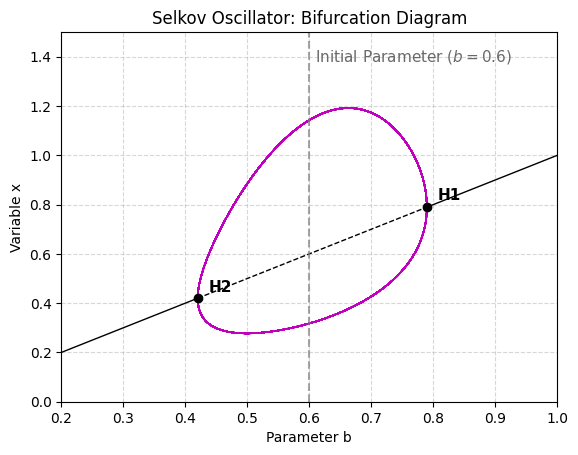

In [9]:
# ==============================================
# 5. Plot the Bifurcation Diagram in (b,x)-Space
# ==============================================
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot using PyDSTool
PyCont.display(('b', 'x'), stability=True)
PyCont['LC1'].display(('b', 'x_min'), stability=True)

ax = plt.gca()

# Filter ALL TEXT tags generated by PyDSTool
for txt in ax.texts:
    txt.set_visible(False)

# Filter ALL MARKER points generated by PyDSTool
for line in ax.get_lines():
    if line.get_linestyle() in ['None', '', ' ']:
        line.set_visible(False)

# Manually re-add clean dots AND labels for the Hopf points
for h_label in ['H1', 'H2']:
    try:
        # Extract the exact coordinates from the equilibrium curve
        pt = PyCont['EQ1'].getSpecialPoint(h_label)
        
        # Plot a prominent black dot ('ko') for the bifurcation point
        plt.plot(pt['b'], pt['x'], 'ko', markersize=6, zorder=5)
        
        # Add a beautifully positioned label
        plt.annotate(h_label, 
                     (pt['b'], pt['x']), 
                     textcoords="offset points", 
                     xytext=(8, 5),  # Offset 8 points right, 5 points up
                     fontsize=11,
                     fontweight='bold',
                     zorder=6)
    except (ValueError, TypeError):
        pass

# ==========================================
# Indicate original parameter choice
# ==========================================
# Plot the vertical dashed line at b = 0.6
plt.axvline(x=0.6, color='gray', linestyle='--', alpha=0.7, zorder=2)

# Add a text label near the top of the line
plt.text(0.61, 1.4, 'Initial Parameter ($b=0.6$)', 
         color='dimgray', fontsize=11, ha='left', va='center', zorder=3)

# Remove the PyDSTool legend if it exists
legend = ax.get_legend()
if legend is not None:
    legend.remove() 

# standard formatting
plt.title('Selkov Oscillator: Bifurcation Diagram')
plt.xlabel('Parameter b')
plt.ylabel('Variable x')
plt.xlim([0.2, 1.0]) 
plt.ylim([-0.0, 1.5]) 
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

In [10]:
# =========================================
# 6A. Two-Parameter Hopf Continuation for H1
# =========================================
PCargs_HB = dst.args(name='HB1', type='H-C2', force=True)
PCargs_HB.description = """Two-parameter Hopf continuation using H-C2 method."""

PCargs_HB.freepars = ['a', 'b'] 
PCargs_HB.initpoint = 'EQ1:H1' 

# Setting
PCargs_HB.MaxNumPoints = 400
PCargs_HB.MaxStepSize = 0.01
PCargs_HB.MinStepSize = 1e-6
PCargs_HB.StepSize = 1e-4

# Restrict LocBifPoints
PCargs_HB.LocBifPoints = ['BT'] 
PCargs_HB.SaveEigen = True

PyCont.newCurve(PCargs_HB)

print('Computing Hopf Bifurcation Curve (H-C2)...')
start = dst.perf_counter()
PyCont['HB1'].forward()
PyCont['HB1'].backward() 
print('HB curve done in %.3f seconds!' % (dst.perf_counter()-start))

# =========================================
# 6B. Two-Parameter Hopf Continuation for H2
# =========================================
PCargs_HB2 = dst.args(name='HB2', type='H-C2', force=True)
PCargs_HB2.description = """Two-parameter Hopf continuation starting from H2."""

PCargs_HB2.freepars = ['a', 'b'] 
PCargs_HB2.initpoint = 'EQ1:H2' # Start from the second Hopf point

# Setting
PCargs_HB2.MaxNumPoints = 400
PCargs_HB2.MaxStepSize = 0.01
PCargs_HB2.MinStepSize = 1e-6
PCargs_HB2.StepSize = 1e-4
PCargs_HB2.LocBifPoints = [] 
PCargs_HB2.SaveEigen = True

PyCont.newCurve(PCargs_HB2)

print('Computing Second Hopf Bifurcation Curve (HB2)...')
start = dst.perf_counter()
PyCont['HB2'].forward()
PyCont['HB2'].backward() 
print('HB2 curve done in %.3f seconds!' % (dst.perf_counter()-start))

Computing Hopf Bifurcation Curve (H-C2)...
HB curve done in 8.935 seconds!
Computing Second Hopf Bifurcation Curve (HB2)...
HB2 curve done in 8.573 seconds!


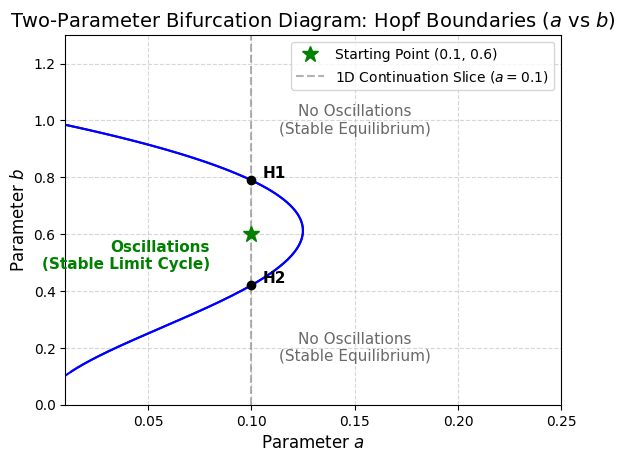

In [12]:
# =======================================
# 7. Plot Two-Parameter Hopf Continuation
# =======================================
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Plot both Hopf boundary curves
PyCont['HB1'].display(('a', 'b'))
PyCont['HB2'].display(('a', 'b'))

ax = plt.gca()

# 1. Mute PyDSTool's default text tags
for txt in ax.texts:
    txt.set_visible(False)

# 2. Squeegee away the noisy artifact markers (keep only continuous lines)
for line in ax.get_lines():
    if line.get_linestyle() in ['None', '', ' ']:
        line.set_visible(False)

# 3. Manually plot and label the Bogdanov-Takens (BT) point if found
try:
    bt_pt = PyCont['HB1'].getSpecialPoint('BT1')
    plt.plot(bt_pt['a'], bt_pt['b'], 'ro', markersize=6, zorder=5) 
    plt.annotate('BT', 
                 (bt_pt['a'], bt_pt['b']), 
                 textcoords="offset points", 
                 xytext=(8, -5), 
                 fontsize=11, 
                 fontweight='bold', 
                 color='red',
                 zorder=6)
except (ValueError, TypeError, KeyError):
    pass

# ==========================================
# Add Region Labels and Initial Point
# ==========================================
# Mark the initial starting point (0.1, 0.6)
plt.plot(0.1, 0.6, 'g*', markersize=12, zorder=4, label='Starting Point (0.1, 0.6)')

# Label the oscillatory region (inside the curve)
plt.text(0.08, 0.58, 'Oscillations\n(Stable Limit Cycle)', 
         fontsize=11, fontweight='bold', color='green', 
         ha='right', va='top', zorder=5)

# Label the non-oscillatory regions (outside the curve)
plt.text(0.15, 1.0, 'No Oscillations\n(Stable Equilibrium)', 
         fontsize=11, color='dimgray', ha='center', va='center')
         
plt.text(0.15, 0.2, 'No Oscillations\n(Stable Equilibrium)', 
         fontsize=11, color='dimgray', ha='center', va='center')

# ==========================================
# Overlay the 1D Continuation Slice
# ==========================================
# Plot the vertical line indicating our 1D continuation in 'b' at fixed a=0.1
plt.axvline(x=0.1, color='gray', linestyle='--', alpha=0.6, zorder=2, label='1D Continuation Slice ($a=0.1$)')

# Retrieve and plot the original H1 and H2 intersections
for h_label in ['H1', 'H2']:
    try:
        # Get the original parameter 'b' for H1 and H2 from the EQ1 curve
        pt = PyCont['EQ1'].getSpecialPoint(h_label)
        b_val = pt['b']
        
        # Plot black dots at the intersections: a=0.1, b=b_val
        plt.plot(0.1, b_val, 'ko', markersize=6, zorder=5)
        
        # Label them clearly
        plt.annotate(h_label, 
                     (0.1, b_val), 
                     textcoords="offset points", 
                     xytext=(8, 2), # Shifted right and slightly up
                     fontsize=11, 
                     fontweight='bold', 
                     zorder=6)
    except (ValueError, TypeError, KeyError):
        pass

# ==========================================
# Formatting
# ==========================================
handles, labels = ax.get_legend_handles_labels()
if handles:
    # Filter legend to only show our custom additions (Starting Point & Slice)
    valid_handles = []
    valid_labels = []
    for h, l in zip(handles, labels):
        if 'Starting' in l or '1D' in l:
            valid_handles.append(h)
            valid_labels.append(l)
            
    if valid_handles:
        ax.legend(valid_handles, valid_labels, loc='upper right')
    else:
        ax.get_legend().remove()

plt.title('Two-Parameter Bifurcation Diagram: Hopf Boundaries ($a$ vs $b$)', fontsize=14)
plt.xlabel('Parameter $a$', fontsize=12)
plt.ylabel('Parameter $b$', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Plot only relevant domain
plt.xlim([0.01, 0.25])
plt.ylim([0.0, 1.3])

plt.show()